# Part 2 of 6: Custom CNN & ResNet18: Models, Training & Tuning

This notebook covers Sections 7–9: the custom CNN and ResNet18, the training engine, hyperparameter tuning, ablations and the selection of both models on the validation set. The ViT is trained in notebook 03.

Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from torchinfo import summary

from plantdisease.config import TRAIN_CONFIG, env, out_path
from plantdisease.data.dataset import prepare
from plantdisease.evaluate import mean_sd
from plantdisease.experiments import register, save_selected
from plantdisease.models import build_model
from plantdisease.plots import finish
from plantdisease.recipe import RunConfig
from plantdisease.train import run

data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache
TUNING_SEED = TRAIN_CONFIG["tuning_seed"]  # one seed for the tuning runs and ablations

## 7. Models

| Model | Type | Idea |
|---|---|---|
| **Custom CNN** | trained from scratch | 4 × (Conv 3×3 → BatchNorm → ReLU → MaxPool), global average pooling, dropout, linear |
| **SE-CNN** | trained from scratch + attention | the same CNN with a **Squeeze-and-Excitation** block after every conv layer. SE squeezes each channel to one number (global average), passes the result through a small bottleneck MLP and uses the sigmoid output to **re-weight the channels**. This is a cheap form of attention that lets the network emphasise lesion-detecting filters (Hu et al., 2018). |
| **ResNet18** | transfer learning (CNN) | ImageNet-pretrained, new 4-class head |
| **ViT-B/16** | transfer learning (transformer) | notebook 03 |

`set_trainable` implements the freezing used for **two-stage fine-tuning**. In the first stage only the new head is trained, so that the randomly initialised layer does not send large, noisy gradients into the pre-trained backbone. In the second stage the backbone is unfrozen and trained with a smaller learning rate. The models are defined in `plantdisease/models.py` (shared with the later notebooks, which rebuild the models from their checkpoints). Their code and layer shapes are shown below.

### Training recipes

Every model is trained with a **recipe** (`RunConfig`, `plantdisease/recipe.py`): architecture, learning rate, batch size, dropout, augmentation, class weights, learning-rate schedule, weight decay, maximum epochs and early-stopping patience, and for pre-trained models the head-only epochs and their learning rates. The base recipes of the custom CNN and of ResNet18 are defined here; Section 9 derives all experiments from them. The maximum epochs and the patience can be set with the environment variables `EPOCHS_*` and `PATIENCE_*` (see the README).

In [2]:
# Base recipe of the custom CNN (with SE attention), trained from scratch
BASE_CNN = RunConfig(
    arch="se_cnn",
    lr=1e-3,
    batch_size=32,
    dropout=0.3,
    augment=True,
    class_weights=True,
    scheduler="cosine",
    weight_decay=1e-4,
    epochs=int(env("EPOCHS_CNN", 50)),
    patience=int(env("PATIENCE_CNN", 10)),
)
# Base recipe of ResNet18: ImageNet-pre-trained, one head-only epoch, then fine-tuning
BASE_RESNET = RunConfig(
    arch="resnet18",
    lr=1e-4,
    batch_size=32,
    augment=True,
    class_weights=True,
    scheduler="cosine",
    weight_decay=1e-4,
    epochs=int(env("EPOCHS_RESNET", 20)),
    patience=int(env("PATIENCE_RESNET", 5)),
    head_epochs=1,
    head_lr=1e-3,
)
# all settings of both recipes (settings that are not listed keep their default)
pd.DataFrame(
    {"custom CNN": BASE_CNN.model_dump(), "ResNet18": BASE_RESNET.model_dump()}
)

,custom CNN,ResNet18
arch,se_cnn,resnet18
lr,0.001,0.0001
batch_size,32,32
dropout,0.3,0.0
augment,True,True
class_weights,True,True
scheduler,cosine,cosine
weight_decay,0.0001,0.0001
epochs,50,20
patience,10,5


The tables below are `torchinfo.summary` of each model for one 224 × 224 RGB image: the output shape and the number of parameters of every layer, and the totals. The global average pooling in `CustomCNN.forward` has no module of its own: it turns the last feature map (256 × 14 × 14) into a vector of 256 values, which is the input of the `dropout` layer.

**Custom CNN**

In [3]:
summary(build_model(BASE_CNN.variant(arch="cnn")), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-5                       [1, 64, 112, 112]         18,432
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8                    [1, 64, 56, 56]           --
│    └─Conv2d: 2-9                       [1, 128, 56, 56]          73,728
│    └─BatchNorm2d: 2-10                 [1, 128, 56, 56]          256
│    └─ReLU: 2-11                        [1, 128, 56, 56]          --
│   

**SE-CNN** (an SEBlock after every ReLU keeps the shape and adds parameters)

In [4]:
summary(build_model(BASE_CNN), input_size=(1, 3, 224, 224), depth=4)

Layer (type:depth-idx)                   Output Shape              Param #
CustomCNN                                [1, 4]                    --
├─Sequential: 1-1                        [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 32, 224, 224]         864
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         --
│    └─SEBlock: 2-4                      [1, 32, 224, 224]         --
│    │    └─Sequential: 3-1              [1, 32]                   --
│    │    │    └─Linear: 4-1             [1, 4]                    132
│    │    │    └─ReLU: 4-2               [1, 4]                    --
│    │    │    └─Linear: 4-3             [1, 32]                   160
│    │    │    └─Sigmoid: 4-4            [1, 32]                   --
│    └─MaxPool2d: 2-5                    [1, 32, 112, 112]         --
│    └─Conv2d: 2-6                       [1, 64, 112, 112]         18,432
│    └─B

**ResNet18**

In [5]:
summary(
    build_model(BASE_RESNET, pretrained=False), input_size=(1, 3, 224, 224), depth=3
)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 4]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           36,864
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           128
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]           --
│

## 8. Training Engine

`run(name, cfg, seed, data)` (`plantdisease/train.py`) trains one configuration with one seed:
- **AdamW** (Adam with decoupled weight decay), optionally with a **cosine learning-rate schedule** stepped every batch;
- **two-stage fine-tuning** for pre-trained models: `head_epochs` epochs training only the head at `head_lr`, then fine-tuning; in the second stage the head and the backbone can have different learning rates (used by the ViT);
- optional class-weighted loss, **gradient clipping** (norm 1) for stability, and **mixed precision** on CUDA;
- **early stopping**: training stops when the validation macro-F1 has not improved for `patience` epochs (`patience` of the recipes in Section 7: 5 epochs for every model). The count starts with the last training stage, so a pre-trained model always fine-tunes for at least `patience` epochs. A cosine schedule keeps its full length, so a run that stops early ends before its learning rate reaches zero;
- **checkpointing**: the weights of the epoch with the best validation macro-F1 are saved (ties keep the earlier epoch). The history and the exact configuration are saved as JSON. If a run with the same configuration already exists, it is loaded instead of retrained;
- **training cost**: per epoch the training time without validation (measured after the GPU has finished), and the number of trainable parameters.

## 9. Hyperparameter Tuning & Ablations (Validation Set Only)

The runs of 9.1 and 9.2 use training seed 62 and are compared by the **best validation macro-F1**. Section 9.3 repeats the best candidates with all training seeds and selects the final models.

**9.1 Custom CNN.** The full recipe is: SE attention, augmentation, dropout 0.3, class-weighted loss, cosine schedule, batch size 32, AdamW (weight decay 1e-4).
- We first sweep the **learning rate** (3e-4, 1e-3, 3e-3).
- Starting from the full recipe at lr 1e-3, we then **remove one component at a time** (ablation). This shows how much each component contributes. It covers the architecture (attention), augmentation, regularisation (dropout), class balancing and the scheduler, plus a **batch-size** variation.

**9.2 Fine-tuning strategies (ResNet18).**
- (a) **frozen backbone**: head only;
- (b) **full fine-tuning with a constant learning rate**;
- (c) **two-stage fine-tuning with a cosine schedule**, at two backbone learning rates;
- (d) starting from (c) at lr 1e-4: **batch size 64**, **no augmentation** and **weight decay 1e-2**.

All experiments are defined in the cell of Section 9.0.

### 9.0 The experiments

All experiments of 9.1 and 9.2 are defined here, as changes of the base recipes of Section 7. `register` makes them known by name to the other notebooks, which rebuild the models from the run names.

In [6]:
cnn_experiments = {
    "SE-CNN (full recipe)": BASE_CNN,
    "SE-CNN lr=3e-4": BASE_CNN.variant(lr=3e-4),
    "SE-CNN lr=3e-3": BASE_CNN.variant(lr=3e-3),
    "CNN (no attention)": BASE_CNN.variant(arch="cnn"),
    "SE-CNN no augmentation": BASE_CNN.variant(augment=False),
    "SE-CNN no dropout": BASE_CNN.variant(dropout=0.0),
    "SE-CNN no class weights": BASE_CNN.variant(class_weights=False),
    "SE-CNN constant lr": BASE_CNN.variant(scheduler="constant"),
    "SE-CNN batch size 64": BASE_CNN.variant(batch_size=64),
}
resnet_experiments = {
    "ResNet18 frozen backbone": BASE_RESNET.variant(
        head_epochs=BASE_RESNET.epochs, scheduler="constant"
    ),
    "ResNet18 full FT, constant lr": BASE_RESNET.variant(
        head_epochs=0, scheduler="constant"
    ),
    "ResNet18 two-stage + cosine, lr=1e-4": BASE_RESNET,
    "ResNet18 two-stage + cosine, lr=3e-4": BASE_RESNET.variant(lr=3e-4),
    "ResNet18 batch size 64": BASE_RESNET.variant(batch_size=64),
    "ResNet18 no augmentation": BASE_RESNET.variant(augment=False),
    "ResNet18 weight decay 1e-2": BASE_RESNET.variant(weight_decay=1e-2),
}
experiments = {**cnn_experiments, **resnet_experiments}
register(experiments)  # the other notebooks find the recipes by name

In [7]:
histories = {
    name: run(name, cfg, TUNING_SEED, data) for name, cfg in cnn_experiments.items()
}


===== SE-CNN (full recipe) (seed 62) =====
Epoch 1/50 [finetune] | train loss 0.5010 acc 0.8126 | val loss 0.5589 acc 0.8151 macro-F1 0.7725 | 19s
Epoch 2/50 [finetune] | train loss 0.3299 acc 0.8805 | val loss 0.1675 acc 0.9275 macro-F1 0.9151 | 5s
Epoch 3/50 [finetune] | train loss 0.2689 acc 0.9065 | val loss 0.2364 acc 0.9175 macro-F1 0.9116 | 5s
Epoch 4/50 [finetune] | train loss 0.2546 acc 0.9098 | val loss 0.1198 acc 0.9659 macro-F1 0.9594 | 5s
Epoch 5/50 [finetune] | train loss 0.2127 acc 0.9233 | val loss 0.2511 acc 0.9075 macro-F1 0.8976 | 5s
Epoch 6/50 [finetune] | train loss 0.1816 acc 0.9416 | val loss 0.1008 acc 0.9644 macro-F1 0.9604 | 6s
Epoch 7/50 [finetune] | train loss 0.1731 acc 0.9395 | val loss 0.1063 acc 0.9616 macro-F1 0.9542 | 6s
Epoch 8/50 [finetune] | train loss 0.1743 acc 0.9416 | val loss 0.1672 acc 0.9374 macro-F1 0.9350 | 6s
Epoch 9/50 [finetune] | train loss 0.1640 acc 0.9398 | val loss 0.0504 acc 0.9815 macro-F1 0.9782 | 5s
Epoch 10/50 [finetune] | tra

In [8]:
histories.update(
    {
        name: run(name, cfg, TUNING_SEED, data)
        for name, cfg in resnet_experiments.items()
    }
)


===== ResNet18 frozen backbone (seed 62) =====
Epoch 1/20 [head] | train loss 0.6385 acc 0.7897 | val loss 0.4061 acc 0.8421 macro-F1 0.7929 | 17s
Epoch 2/20 [head] | train loss 0.3162 acc 0.9061 | val loss 0.2790 acc 0.8890 macro-F1 0.8607 | 5s
Epoch 3/20 [head] | train loss 0.2419 acc 0.9230 | val loss 0.2158 acc 0.9175 macro-F1 0.9090 | 5s
Epoch 4/20 [head] | train loss 0.2197 acc 0.9318 | val loss 0.1864 acc 0.9360 macro-F1 0.9306 | 5s
Epoch 5/20 [head] | train loss 0.2030 acc 0.9343 | val loss 0.1510 acc 0.9516 macro-F1 0.9446 | 5s
Epoch 6/20 [head] | train loss 0.1921 acc 0.9407 | val loss 0.1815 acc 0.9275 macro-F1 0.9126 | 5s
Epoch 7/20 [head] | train loss 0.1763 acc 0.9422 | val loss 0.1567 acc 0.9431 macro-F1 0.9338 | 5s
Epoch 8/20 [head] | train loss 0.1721 acc 0.9437 | val loss 0.1400 acc 0.9502 macro-F1 0.9442 | 5s
Epoch 9/20 [head] | train loss 0.1623 acc 0.9514 | val loss 0.1439 acc 0.9431 macro-F1 0.9350 | 5s
Epoch 10/20 [head] | train loss 0.1583 acc 0.9493 | val loss

In [9]:
def summarize(name, h, cfg):
    # One row of the tuning table: the recipe and its best validation epoch.
    best = int(np.argmax(h.val_f1))
    return {
        "run": name,
        "arch": cfg.arch,
        "lr": cfg.lr,
        "batch": cfg.batch_size,
        "dropout": cfg.dropout,
        "augment": cfg.augment,
        "class_w": cfg.class_weights,
        "schedule": cfg.scheduler,
        "best_epoch": best + 1,
        "val_acc": h.val_acc[best],
        "val_macro_f1": h.val_f1[best],
        "train_s_per_epoch": np.mean(h.train_time),
    }


tuning = pd.DataFrame(
    [summarize(n, histories[n], experiments[n]) for n in histories]
).set_index("run")
tuning.to_csv(out_path("tuning_results.csv"))

tuning.round(4)

,arch,lr,batch,dropout,augment,class_w,schedule,best_epoch,val_acc,val_macro_f1,train_s_per_epoch
run,,,,,,,,,,,
SE-CNN (full recipe),se_cnn,0.0010,32,0.3,True,True,cosine,37,0.9972,0.9965,5.4897
SE-CNN lr=3e-4,se_cnn,0.0003,32,0.3,True,True,cosine,34,0.9929,0.9917,6.1682
SE-CNN lr=3e-3,se_cnn,0.0030,32,0.3,True,True,cosine,32,0.9957,0.9948,5.4989
CNN (no attention),cnn,0.0010,32,0.3,True,True,cosine,41,0.9943,0.9934,4.7466
SE-CNN no augmentation,se_cnn,0.0010,32,0.3,False,True,cosine,16,0.9943,0.9939,5.5629
SE-CNN no dropout,se_cnn,0.0010,32,0.0,True,True,cosine,19,0.9929,0.9921,5.5003
SE-CNN no class weights,se_cnn,0.0010,32,0.3,True,False,cosine,40,0.9943,0.9935,5.4867
SE-CNN constant lr,se_cnn,0.0010,32,0.3,True,True,constant,19,0.9886,0.9873,5.8491
SE-CNN batch size 64,se_cnn,0.0010,64,0.3,True,True,cosine,39,0.9943,0.9934,5.6437


### 9.3 Do the best candidates stay on top? Selection with all seeds

Differences between neighbouring configurations are often smaller than the run-to-run variation, so a single seed cannot rank them reliably. The three best CNN variants and the two best ResNet18 variants (by the validation macro-F1 of seed 62) are therefore repeated with all training seeds. The **final models are chosen by the mean validation macro-F1 over the seeds**, shown with the standard deviation over the seeds. The test set is not used here.

In [10]:
# Model selection on the validation set: the best candidates are repeated with all training seeds
TOP_K = {"cnn": 3, "resnet18": 2}  # candidates per family
families = {"cnn": cnn_experiments, "resnet18": resnet_experiments}
rows = []
for family, configs in families.items():
    top = tuning.loc[list(configs), "val_macro_f1"].nlargest(TOP_K[family]).index
    for name in top:
        scores = [
            max(run(name, configs[name], seed, data).val_f1)
            for seed in TRAIN_CONFIG["seeds"]
        ]
        rows.append(
            {
                "family": family,
                "run": name,
                f"val macro-F1 (seed {TUNING_SEED})": tuning.at[name, "val_macro_f1"],
                "mean over seeds": np.mean(scores),
                "mean ± sd": mean_sd(scores),
            }
        )
multi_seed = pd.DataFrame(rows).set_index("run")
multi_seed.to_csv(out_path("tuning_multi_seed.csv"))

selected = {}  # family -> the candidate with the best mean over the seeds
for family in families:
    best = multi_seed.loc[multi_seed.family == family, "mean over seeds"].idxmax()
    selected[family] = best
    save_selected(family, best)  # OUT_DIR/final_models.json, read by notebooks 04-06
    print(f"Selected {family}: {best}")
multi_seed.round(4)

Loaded finished run: SE-CNN (full recipe) (seed 62)

===== SE-CNN (full recipe) (seed 63) =====
Epoch 1/50 [finetune] | train loss 0.5347 acc 0.8053 | val loss 0.2737 acc 0.9161 macro-F1 0.9114 | 19s
Epoch 2/50 [finetune] | train loss 0.3051 acc 0.8884 | val loss 0.1690 acc 0.9445 macro-F1 0.9328 | 6s
Epoch 3/50 [finetune] | train loss 0.2552 acc 0.9110 | val loss 0.3209 acc 0.8691 macro-F1 0.8317 | 6s
Epoch 4/50 [finetune] | train loss 0.2383 acc 0.9156 | val loss 0.1333 acc 0.9573 macro-F1 0.9496 | 6s
Epoch 5/50 [finetune] | train loss 0.2000 acc 0.9297 | val loss 0.7692 acc 0.7397 macro-F1 0.7190 | 6s
Epoch 6/50 [finetune] | train loss 0.2080 acc 0.9260 | val loss 0.2057 acc 0.9104 macro-F1 0.8976 | 6s
Epoch 7/50 [finetune] | train loss 0.1545 acc 0.9437 | val loss 0.0677 acc 0.9758 macro-F1 0.9716 | 6s
Epoch 8/50 [finetune] | train loss 0.1484 acc 0.9529 | val loss 0.0678 acc 0.9787 macro-F1 0.9746 | 6s
Epoch 9/50 [finetune] | train loss 0.1537 acc 0.9529 | val loss 0.0492 acc 0.98

,family,val macro-F1 (seed 62),mean over seeds,mean ± sd
run,,,,
SE-CNN (full recipe),cnn,0.9965,0.9953,0.9953 ± 0.0010
SE-CNN lr=3e-3,cnn,0.9948,0.9936,0.9936 ± 0.0036
SE-CNN no augmentation,cnn,0.9939,0.9952,0.9952 ± 0.0013
"ResNet18 two-stage + cosine, lr=1e-4",resnet18,1.0000,0.9988,0.9988 ± 0.0010
ResNet18 weight decay 1e-2,resnet18,0.9983,0.9989,0.9989 ± 0.0010


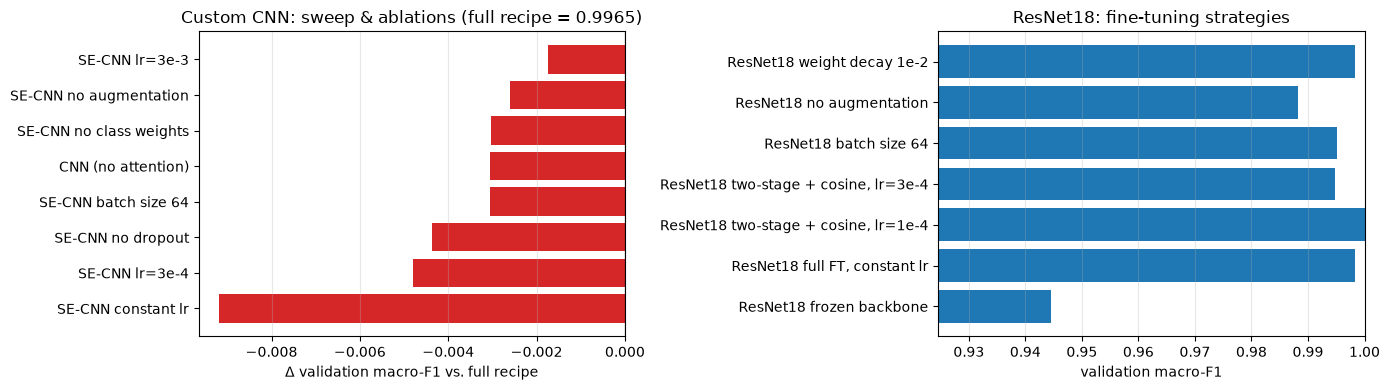

In [11]:
# Ablation chart: change in validation macro-F1 relative to the full CNN recipe
ref = tuning.loc["SE-CNN (full recipe)", "val_macro_f1"]
delta = (tuning.loc[list(cnn_experiments)[1:], "val_macro_f1"] - ref).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].barh(
    delta.index,
    delta.values,
    color=["tab:red" if d < 0 else "tab:green" for d in delta.values],
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Δ validation macro-F1 vs. full recipe")
axes[0].set_title(f"Custom CNN: sweep & ablations (full recipe = {ref:.4f})")
ft = tuning.loc[list(resnet_experiments), "val_macro_f1"]
axes[1].barh(ft.index, ft.values, color="tab:blue")
axes[1].set_xlim(ft.min() - 0.02, 1.0)
axes[1].set_xlabel("validation macro-F1")
axes[1].set_title("ResNet18: fine-tuning strategies")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
finish("ablations.png")

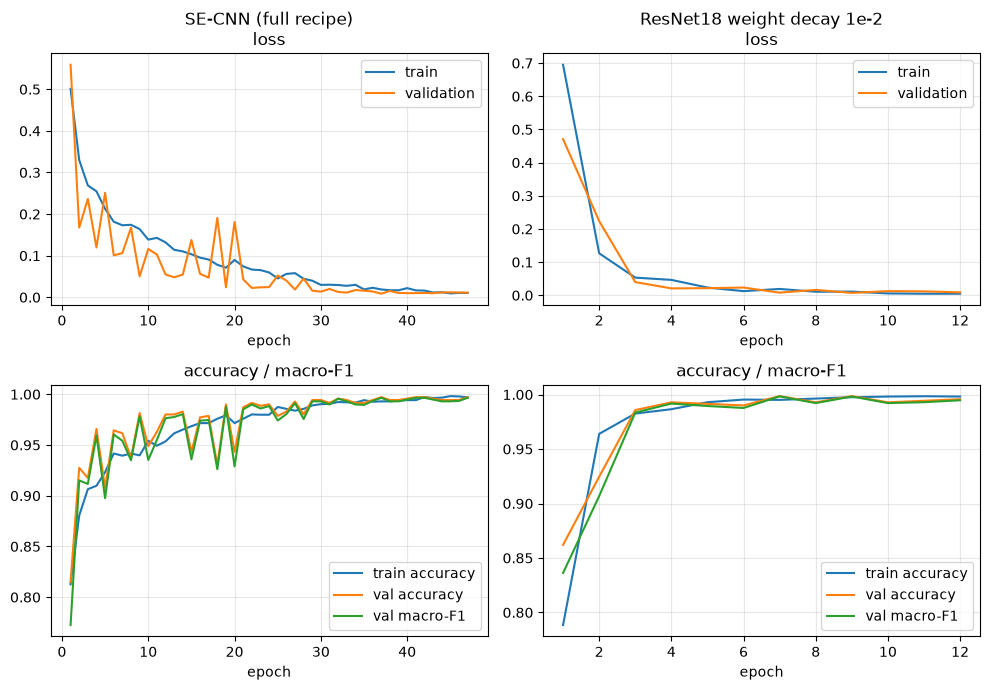

In [12]:
# Learning curves of the selected models (tuning seed)
fig, axes = plt.subplots(2, len(selected), figsize=(5 * len(selected), 7))
for col, name in enumerate(selected.values()):
    h = histories[name]
    epochs = range(1, len(h.train_loss) + 1)
    axes[0, col].plot(epochs, h.train_loss, label="train")
    axes[0, col].plot(epochs, h.val_loss, label="validation")
    axes[0, col].set_title(f"{name}\nloss")
    axes[1, col].plot(epochs, h.train_acc, label="train accuracy")
    axes[1, col].plot(epochs, h.val_acc, label="val accuracy")
    axes[1, col].plot(epochs, h.val_f1, label="val macro-F1")
    axes[1, col].set_title("accuracy / macro-F1")
    for ax in axes[:, col]:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
        ax.legend()
finish("learning_curves.png")